# 03 — Municipal Exploratory Analysis and Sensitivity Checks

This notebook consolidates the exploratory municipality-level analyses that motivated the final regression models.

It preserves the original 2024 electricity/adoption exploration, tourism/seasonality sensitivity checks, and comparisons of full-displacement, partial-displacement, and overall heat-pump adoption measures.


## Source provenance

This polished notebook consolidates the following original work:

- `2024_eda.ipynb` — 2024 municipal electricity cleaning, winter/summer ratios, heat-pump adoption merging, correlations, and missing/suppressed-data exploration.
- `eda_notouristtowns.ipynb` — Sensitivity analysis excluding a manually defined set of tourist/seasonal municipalities and comparing adoption/electricity relationships.
- `partial_analysis(1).ipynb` — Exploration of full-displacement, partial-displacement, and overall adoption measures, including high-adoption towns and coastal/inland comparisons.

No analytical code from the source files was silently replaced. The purpose of this version is to make the workflow easier to follow in a public research repository.


---
## Original analysis section: `2024_eda.ipynb`

**What this section contains:** 2024 municipal electricity cleaning, winter/summer ratios, heat-pump adoption merging, correlations, and missing/suppressed-data exploration.

> The code and outputs below are preserved from the original notebook/work file. They have not been rewritten or re-derived for this polished repository version.


In [3]:
import pandas as pd

df_elec = pd.read_csv("/content/electricity_residential_2024_clean.csv")   # or read_excel if needed

In [4]:
df_elec.columns = df_elec.columns.str.strip()

In [5]:
df_elec["Winter_MWh"] = df_elec["Jan"] + df_elec["Feb"] + df_elec["Mar"]
df_elec["Summer_MWh"] = df_elec["Jun"] + df_elec["Jul"] + df_elec["Aug"]

In [6]:
df_elec["Winter_Summer_Ratio"] = df_elec["Winter_MWh"] / df_elec["Summer_MWh"]

In [7]:
print(df_elec.columns)

Index(['Municipality', 'Sector', 'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
       'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec', 'Total', 'Winter_MWh',
       'Summer_MWh', 'Winter_Summer_Ratio'],
      dtype='object')


In [8]:
df_elec.columns = df_elec.columns.str.strip().str.lower()

In [9]:
df_elec_clean = df_elec[[
    "municipality",
    "winter_mwh",
    "summer_mwh",
    "winter_summer_ratio"
]]

In [10]:
df_hp = pd.read_csv("/content/ma_heatpump_installs_per_1000_all_towns.csv")

df_hp["municipality"] = df_hp["municipality"].str.lower().str.strip()

In [11]:
df_final = pd.merge(
    df_elec_clean,
    df_hp,
    on="municipality",
    how="inner"
)

In [12]:
df_final.to_csv("ma_2024_final_analysis_dataset.csv", index=False)

In [13]:
import pandas as pd

# clean columns
df_elec.columns = df_elec.columns.str.strip().str.lower()
df_hp.columns = df_hp.columns.str.strip().str.lower()

# keep needed electricity columns
df_elec_clean = df_elec[[
    "municipality",
    "winter_mwh",
    "summer_mwh",
    "winter_summer_ratio"
]].copy()

# clean municipality names in both
df_elec_clean["municipality"] = (
    df_elec_clean["municipality"].astype(str).str.strip().str.lower()
)

df_hp["municipality"] = (
    df_hp["municipality"].astype(str).str.strip().str.lower()
)

# merge
df_final = pd.merge(df_elec_clean, df_hp, on="municipality", how="inner")

print("Electricity shape:", df_elec_clean.shape)
print("Heat pump shape:", df_hp.shape)
print("Final merged shape:", df_final.shape)

df_final.head()

Electricity shape: (301, 4)
Heat pump shape: (345, 8)
Final merged shape: (301, 11)


,municipality,winter_mwh,summer_mwh,winter_summer_ratio,hp_accounts,hp_locations,households,electric_fuel,gas_fuel,delivered_fuels,installs_per_1000
0,abington,12448.0,15969.0,0.779510,209.0,202.0,6438.0,1053.0,2774.0,2570.0,32.463498
1,acton,19043.0,20368.0,0.934947,780.0,765.0,9085.0,1483.0,4787.0,2815.0,85.855806
2,acushnet,7597.0,9960.0,0.762751,213.0,208.0,4103.0,148.0,1758.0,2066.0,51.913234
3,adams,5899.0,6183.0,0.954068,105.0,100.0,4081.0,333.0,2156.0,1547.0,25.728988
4,agawam,22022.0,27900.0,0.789319,332.0,329.0,11792.0,2154.0,6512.0,3023.0,28.154681


In [14]:
df_final.to_csv("ma_2024_final_analysis_dataset.csv", index=False)

In [15]:
from google.colab import files
files.download("ma_2024_final_analysis_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
len(df_hp["municipality"].unique())
len(df_elec_clean["municipality"].unique())

301

In [17]:
hp_towns = set(df_hp["municipality"])
elec_towns = set(df_elec_clean["municipality"])

missing = hp_towns - elec_towns

print(len(missing))
print(sorted(list(missing))[:20])

44
['ashburnham', 'belmont', 'boxborough', 'boylston', 'braintree', 'chester', 'chicopee', 'concord', 'danvers', 'dighton', 'georgetown', 'groton', 'groveland', 'hingham', 'holden', 'hudson', 'hull', 'ipswich', 'lakeville', 'littleton']


In [18]:
missing_df = pd.DataFrame(sorted(list(missing)), columns=["municipality"])

In [19]:
missing_df.to_csv("missing_mlp_towns_2024.csv", index=False)

In [20]:
from google.colab import files
files.download("missing_mlp_towns_2024.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
corr = df_final[[
    "installs_per_1000",
    "winter_summer_ratio",
    "electric_fuel",
    "gas_fuel",
    "delivered_fuels"
]].corr()

corr

,installs_per_1000,winter_summer_ratio,electric_fuel,gas_fuel,delivered_fuels
installs_per_1000,1.000000,0.237981,-0.221733,-0.307408,-0.334278
winter_summer_ratio,0.237981,1.000000,-0.091390,-0.202376,-0.246551
electric_fuel,-0.221733,-0.091390,1.000000,0.956545,0.801593
gas_fuel,-0.307408,-0.202376,0.956545,1.000000,0.799400
delivered_fuels,-0.334278,-0.246551,0.801593,0.799400,1.000000


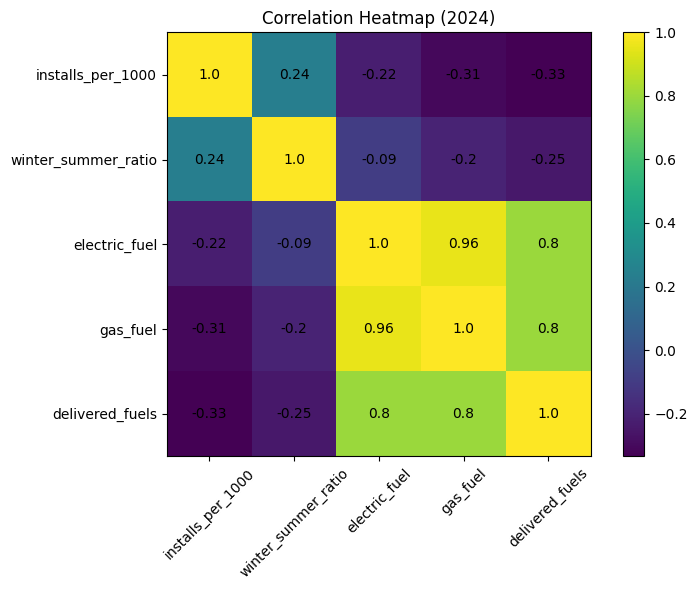

In [22]:
import matplotlib.pyplot as plt

corr = df_final[[
    "installs_per_1000",
    "winter_summer_ratio",
    "electric_fuel",
    "gas_fuel",
    "delivered_fuels"
]].corr()

plt.figure(figsize=(8,6))
plt.imshow(corr)

plt.colorbar()

plt.xticks(range(len(corr.columns)), corr.columns, rotation=45)
plt.yticks(range(len(corr.columns)), corr.columns)

# add values inside cells
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, round(corr.iloc[i, j], 2),
                 ha="center", va="center", color="black")

plt.title("Correlation Heatmap (2024)")
plt.tight_layout()
plt.show()

In [23]:
df_2013 = pd.read_csv("/content/ma_heatpump_final_analysis_dataset.csv")
df_2024 = pd.read_csv("/content/ma_2024_final_analysis_dataset.csv")

In [25]:
df_2013.columns = df_2013.columns.str.strip().str.lower()
df_2024.columns = df_2024.columns.str.strip().str.lower()

In [26]:
print(df_2013.columns)
print(df_2024.columns)

Index(['municipality', 'annual_mwh', 'winter_mwh', 'summer_mwh',
       'winter_summer_ratio', 'highest_winter_month', 'summer_avg_mwh',
       'highest_winter_month_ratio', 'hp_accounts', 'households',
       'electric_fuel', 'gas_fuel', 'delivered_fuels', 'installs_per_1000'],
      dtype='object')
Index(['municipality', 'winter_mwh', 'summer_mwh', 'winter_summer_ratio',
       'hp_accounts', 'hp_locations', 'households', 'electric_fuel',
       'gas_fuel', 'delivered_fuels', 'installs_per_1000'],
      dtype='object')


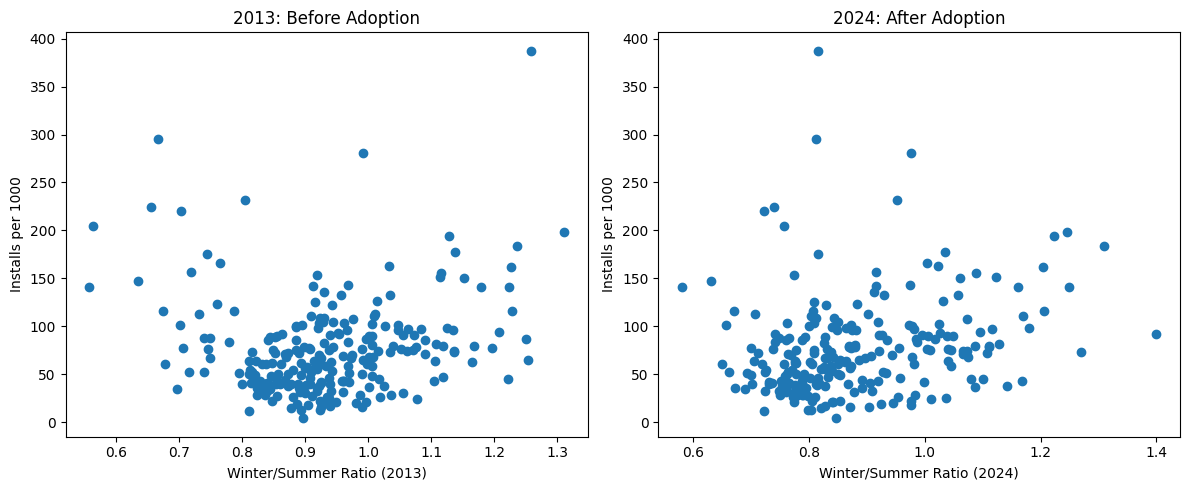

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

# 2013
plt.subplot(1,2,1)
plt.scatter(df_2013["winter_summer_ratio"], df_2013["installs_per_1000"])
plt.xlabel("Winter/Summer Ratio (2013)")
plt.ylabel("Installs per 1000")
plt.title("2013: Before Adoption")

# 2024
plt.subplot(1,2,2)
plt.scatter(df_2024["winter_summer_ratio"], df_2024["installs_per_1000"])
plt.xlabel("Winter/Summer Ratio (2024)")
plt.ylabel("Installs per 1000")
plt.title("2024: After Adoption")

plt.tight_layout()
plt.show()

In [28]:
corr_2013 = df_2013[["installs_per_1000","winter_summer_ratio"]].corr().iloc[0,1]
corr_2024 = df_2024[["installs_per_1000","winter_summer_ratio"]].corr().iloc[0,1]

print("2013:", corr_2013)
print("2024:", corr_2024)

2013: 0.1022251373992073
2024: 0.23798129988732578


In [29]:
df_2013["winter_summer_ratio"].describe()
df_2024["winter_summer_ratio"].describe()

,winter_summer_ratio
count,301.000000
mean,0.941560
std,0.190536
min,0.580117
25%,0.799272
50%,0.890818
75%,1.061248
max,1.970362


In [30]:
df_2013["winter_summer_ratio"].std()
df_2024["winter_summer_ratio"].std()

0.1905363758640799

In [31]:
df_2024.sort_values("winter_summer_ratio", ascending=False).head(10)

,municipality,winter_mwh,summer_mwh,winter_summer_ratio,hp_accounts,hp_locations,households,electric_fuel,gas_fuel,delivered_fuels,installs_per_1000
105,hancock,1795.0,911.0,1.970362,NaN,NaN,316.0,75.0,14.0,221.0,NaN
165,mount washington,371.0,242.0,1.533058,NaN,NaN,85.0,10.0,0.0,70.0,NaN
202,plainfield,714.0,487.0,1.466119,NaN,NaN,261.0,14.0,0.0,223.0,NaN
220,sandisfield,1727.0,1180.0,1.463559,NaN,NaN,343.0,28.0,18.0,287.0,NaN
113,hawley,335.0,234.0,1.431624,NaN,NaN,135.0,9.0,6.0,116.0,NaN
154,middlefield,595.0,418.0,1.423445,NaN,NaN,172.0,5.0,6.0,161.0,NaN
7,amherst,20232.0,14454.0,1.399751,830.0,769.0,9039.0,3330.0,2193.0,3312.0,91.824317
60,cummington,983.0,712.0,1.380618,NaN,NaN,400.0,20.0,10.0,359.0,NaN
87,florida,611.0,448.0,1.363839,NaN,NaN,315.0,25.0,5.0,274.0,NaN
21,becket,3652.0,2707.0,1.349095,NaN,NaN,929.0,47.0,11.0,813.0,NaN


In [32]:
len(df_2013[df_2013["winter_summer_ratio"] > 1])
len(df_2024[df_2024["winter_summer_ratio"] > 1])

104

In [33]:
top_2013 = df_2013.sort_values("installs_per_1000", ascending=False).head(20)
top_2024 = df_2024.sort_values("installs_per_1000", ascending=False).head(20)

In [34]:
df_2013 = pd.read_csv("/content/ma_heatpump_final_analysis_dataset.csv")
df_2024 = pd.read_csv("/content/ma_2024_final_analysis_dataset.csv")

In [35]:
df_2013.columns = df_2013.columns.str.strip().str.lower()
df_2024.columns = df_2024.columns.str.strip().str.lower()

In [36]:
df_2013_small = df_2013[[
    "municipality",
    "winter_summer_ratio"
]].rename(columns={
    "winter_summer_ratio": "ratio_2013"
})

df_2024_small = df_2024[[
    "municipality",
    "winter_summer_ratio",
    "installs_per_1000"
]].rename(columns={
    "winter_summer_ratio": "ratio_2024"
})

In [37]:
df_combined = pd.merge(
    df_2013_small,
    df_2024_small,
    on="municipality",
    how="inner"
)

In [39]:
df_combined["ratio_change"] = df_combined["ratio_2024"] - df_combined["ratio_2013"]

In [40]:
df_combined.head()

,municipality,ratio_2013,ratio_2024,installs_per_1000,ratio_change
0,hancock,2.579768,1.970362,NaN,-0.609406
1,charlemont,1.677205,1.285466,NaN,-0.391739
2,washington,1.623301,1.171815,NaN,-0.451486
3,sandisfield,1.528114,1.463559,NaN,-0.064555
4,windsor,1.377729,1.271605,NaN,-0.106124


In [41]:
df_combined.to_csv("combined_2013_2024_analysis.csv", index=False)

In [42]:
df_combined.sort_values("ratio_change", ascending=False).head(10)

,municipality,ratio_2013,ratio_2024,installs_per_1000,ratio_change
141,amherst,0.953752,1.399751,91.824317,0.445998
91,rowe,1.027759,1.287425,NaN,0.259666
270,tisbury,0.765014,1.003388,165.959703,0.238374
207,williamstown,0.890233,1.107018,72.222222,0.216785
279,oak bluffs,0.717865,0.915471,156.492248,0.197606
230,northampton,0.855224,1.049354,89.348451,0.194130
291,chilmark,0.563276,0.757297,205.035971,0.194021
11,plainfield,1.275362,1.466119,NaN,0.190757
100,williamsburg,1.008258,1.168785,110.815603,0.160527
288,aquinnah,0.660633,0.816800,NaN,0.156167


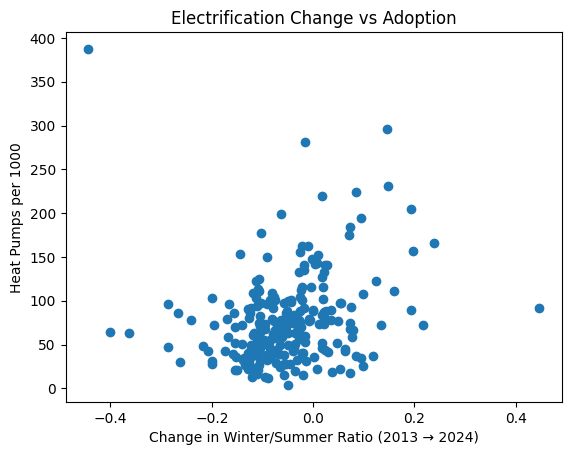

In [43]:
plt.scatter(df_combined["ratio_change"], df_combined["installs_per_1000"])
plt.xlabel("Change in Winter/Summer Ratio (2013 → 2024)")
plt.ylabel("Heat Pumps per 1000")
plt.title("Electrification Change vs Adoption")
plt.show()

In [44]:
df_combined[["ratio_change", "installs_per_1000"]].corr()

,ratio_change,installs_per_1000
ratio_change,1.00000,0.20017
installs_per_1000,0.20017,1.00000


---
## Original analysis section: `eda_notouristtowns.ipynb`

**What this section contains:** Sensitivity analysis excluding a manually defined set of tourist/seasonal municipalities and comparing adoption/electricity relationships.

> The code and outputs below are preserved from the original notebook/work file. They have not been rewritten or re-derived for this polished repository version.


In [1]:
from google.colab import files
uploaded = files.upload()

Saving 2013_ma_heatpump_final_analysis_dataset.csv to 2013_ma_heatpump_final_analysis_dataset.csv


In [2]:
from google.colab import files
uploaded = files.upload()

Saving ma_2024_final_analysis_dataset.csv to ma_2024_final_analysis_dataset.csv


In [3]:
import pandas as pd

df_2024 = pd.read_csv("ma_2024_final_analysis_dataset.csv")
df_2013 = pd.read_csv("2013_ma_heatpump_final_analysis_dataset.csv")

print("2024 shape:", df_2024.shape)
print("2013 shape:", df_2013.shape)

df_2024.head()

2024 shape: (301, 11)
2013 shape: (351, 14)


,municipality,winter_mwh,summer_mwh,winter_summer_ratio,hp_accounts,hp_locations,households,electric_fuel,gas_fuel,delivered_fuels,installs_per_1000
0,abington,12448.0,15969.0,0.779510,209.0,202.0,6438.0,1053.0,2774.0,2570.0,32.463498
1,acton,19043.0,20368.0,0.934947,780.0,765.0,9085.0,1483.0,4787.0,2815.0,85.855806
2,acushnet,7597.0,9960.0,0.762751,213.0,208.0,4103.0,148.0,1758.0,2066.0,51.913234
3,adams,5899.0,6183.0,0.954068,105.0,100.0,4081.0,333.0,2156.0,1547.0,25.728988
4,agawam,22022.0,27900.0,0.789319,332.0,329.0,11792.0,2154.0,6512.0,3023.0,28.154681


In [4]:
df_2024["municipality"] = df_2024["municipality"].str.strip().str.lower()
df_2013["municipality"] = df_2013["municipality"].str.strip().str.lower()

In [5]:
tourist_towns = [
    # Cape Cod
    "barnstable", "yarmouth", "dennis", "harwich", "brewster", "chatham",
    "orleans", "eastham", "wellfleet", "truro", "provincetown",
    "sandwich", "falmouth", "mashpee", "bourne",

    # Islands
    "nantucket", "edgartown", "oak bluffs", "tisbury",
    "west tisbury", "chilmark", "aquinnah",

    # Berkshires / second homes
    "great barrington", "lenox", "stockbridge", "lee", "pittsfield",
    "north adams", "williamstown", "hancock", "lanesborough",
    "new marlborough", "monterey", "otis", "sandisfield",
    "tyringham", "alford", "egremont", "sheffield", "mount washington",

    # Coastal tourism
    "gloucester", "rockport", "manchester-by-the-sea",
    "essex", "newburyport", "salisbury",

    # Small seasonal towns
    "rowe", "florida", "savoy", "hawley", "heath",
    "windsor", "peru", "cummington", "worthington"
]

In [6]:
df_2024["is_tourist"] = df_2024["municipality"].isin(tourist_towns)
df_2013["is_tourist"] = df_2013["municipality"].isin(tourist_towns)

print(df_2024["is_tourist"].value_counts())
print(df_2013["is_tourist"].value_counts())

is_tourist
False    246
True      55
Name: count, dtype: int64
is_tourist
False    296
True      55
Name: count, dtype: int64


In [7]:
df_2024_clean = df_2024[df_2024["is_tourist"] == False].copy()
df_2013_clean = df_2013[df_2013["is_tourist"] == False].copy()

print("2024 cleaned:", df_2024_clean.shape)
print("2013 cleaned:", df_2013_clean.shape)

2024 cleaned: (246, 12)
2013 cleaned: (296, 15)


In [9]:
# Check distributions
print(df_2024_clean["winter_summer_ratio"].describe())
print(df_2013_clean["Winter_Summer_Ratio"].describe())

count    246.000000
mean       0.925824
std        0.163421
min        0.661154
25%        0.799616
50%        0.875722
75%        1.036941
max        1.466119
Name: winter_summer_ratio, dtype: float64
count    242.000000
mean       0.979609
std        0.144526
min        0.696442
25%        0.884980
50%        0.941524
75%        1.054888
max        1.677205
Name: Winter_Summer_Ratio, dtype: float64


Correlation

In [10]:
df_2024_clean[[
    "installs_per_1000",
    "winter_summer_ratio",
    "electric_fuel",
    "gas_fuel",
    "delivered_fuels"
]].corr()

,installs_per_1000,winter_summer_ratio,electric_fuel,gas_fuel,delivered_fuels
installs_per_1000,1.000000,0.521804,-0.269454,-0.370539,-0.354833
winter_summer_ratio,0.521804,1.000000,-0.081506,-0.199202,-0.217291
electric_fuel,-0.269454,-0.081506,1.000000,0.959312,0.814321
gas_fuel,-0.370539,-0.199202,0.959312,1.000000,0.805496
delivered_fuels,-0.354833,-0.217291,0.814321,0.805496,1.000000


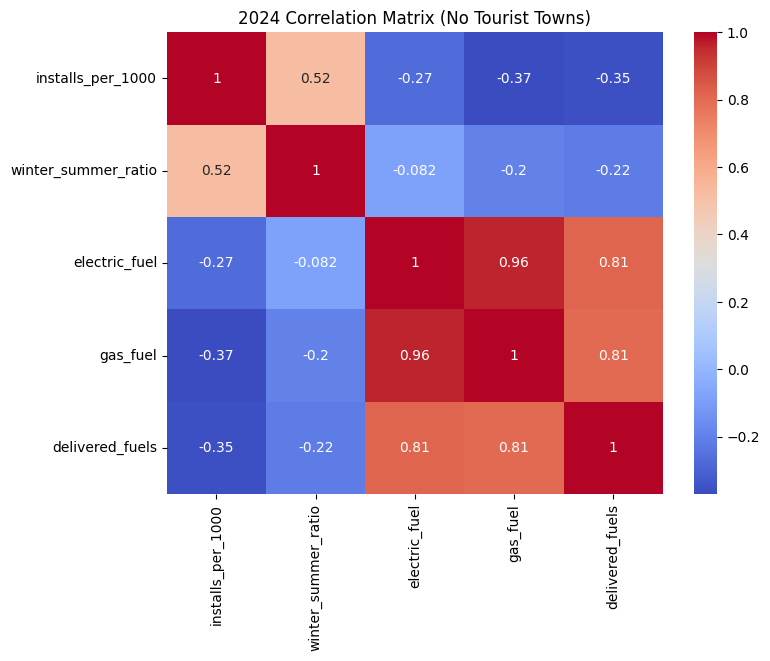

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

sns.heatmap(
    df_2024_clean[[
        "installs_per_1000",
        "winter_summer_ratio",
        "electric_fuel",
        "gas_fuel",
        "delivered_fuels"
    ]].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("2024 Correlation Matrix (No Tourist Towns)")
plt.show()

In [12]:
df_2013_clean[[
    "installs_per_1000",
    "Winter_Summer_Ratio",
    "electric_fuel",
    "gas_fuel",
    "delivered_fuels"
]].corr()

,installs_per_1000,Winter_Summer_Ratio,electric_fuel,gas_fuel,delivered_fuels
installs_per_1000,1.000000,0.446620,-0.252562,-0.356670,-0.344815
Winter_Summer_Ratio,0.446620,1.000000,-0.074151,-0.160541,-0.233982
electric_fuel,-0.252562,-0.074151,1.000000,0.957693,0.794696
gas_fuel,-0.356670,-0.160541,0.957693,1.000000,0.785877
delivered_fuels,-0.344815,-0.233982,0.794696,0.785877,1.000000


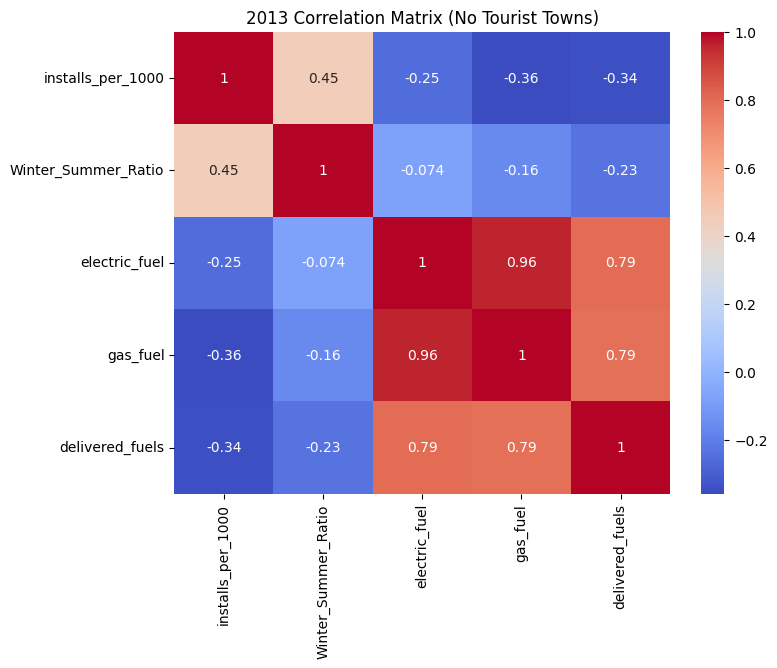

In [13]:
plt.figure(figsize=(8,6))

sns.heatmap(
    df_2013_clean[[
        "installs_per_1000",
        "Winter_Summer_Ratio",
        "electric_fuel",
        "gas_fuel",
        "delivered_fuels"
    ]].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("2013 Correlation Matrix (No Tourist Towns)")
plt.show()

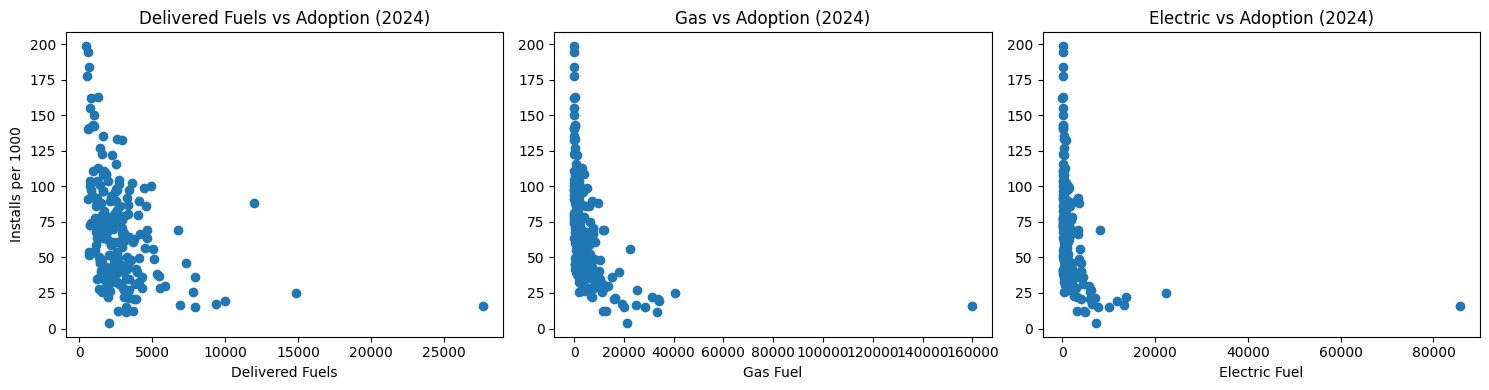

In [14]:
plt.figure(figsize=(15,4))

# Delivered fuels
plt.subplot(1,3,1)
plt.scatter(df_2024_clean["delivered_fuels"], df_2024_clean["installs_per_1000"])
plt.title("Delivered Fuels vs Adoption (2024)")
plt.xlabel("Delivered Fuels")
plt.ylabel("Installs per 1000")

# Gas
plt.subplot(1,3,2)
plt.scatter(df_2024_clean["gas_fuel"], df_2024_clean["installs_per_1000"])
plt.title("Gas vs Adoption (2024)")
plt.xlabel("Gas Fuel")

# Electric
plt.subplot(1,3,3)
plt.scatter(df_2024_clean["electric_fuel"], df_2024_clean["installs_per_1000"])
plt.title("Electric vs Adoption (2024)")
plt.xlabel("Electric Fuel")

plt.tight_layout()
plt.show()

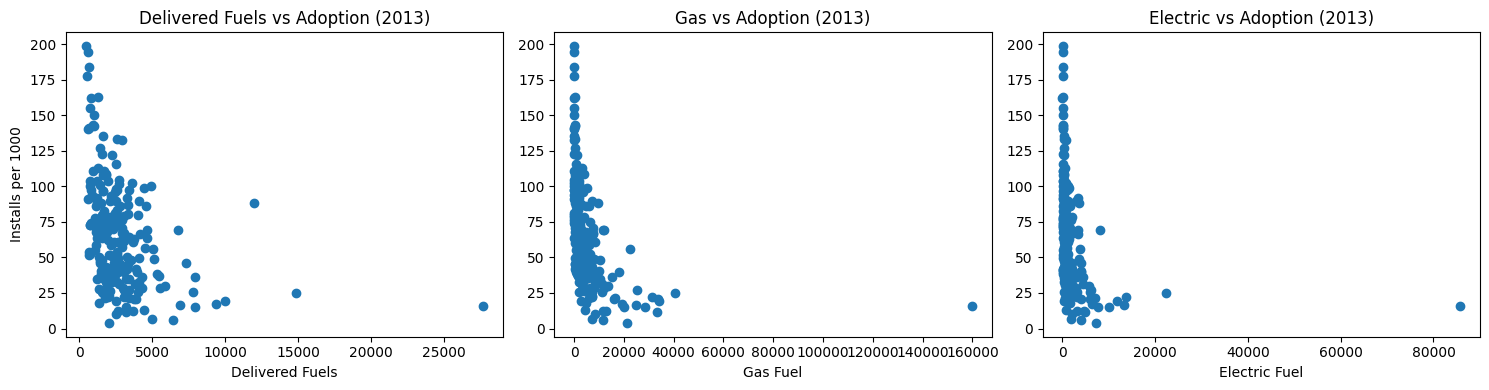

In [15]:
plt.figure(figsize=(15,4))

# Delivered fuels
plt.subplot(1,3,1)
plt.scatter(df_2013_clean["delivered_fuels"], df_2013_clean["installs_per_1000"])
plt.title("Delivered Fuels vs Adoption (2013)")
plt.xlabel("Delivered Fuels")
plt.ylabel("Installs per 1000")

# Gas
plt.subplot(1,3,2)
plt.scatter(df_2013_clean["gas_fuel"], df_2013_clean["installs_per_1000"])
plt.title("Gas vs Adoption (2013)")
plt.xlabel("Gas Fuel")

# Electric
plt.subplot(1,3,3)
plt.scatter(df_2013_clean["electric_fuel"], df_2013_clean["installs_per_1000"])
plt.title("Electric vs Adoption (2013)")
plt.xlabel("Electric Fuel")

plt.tight_layout()
plt.show()

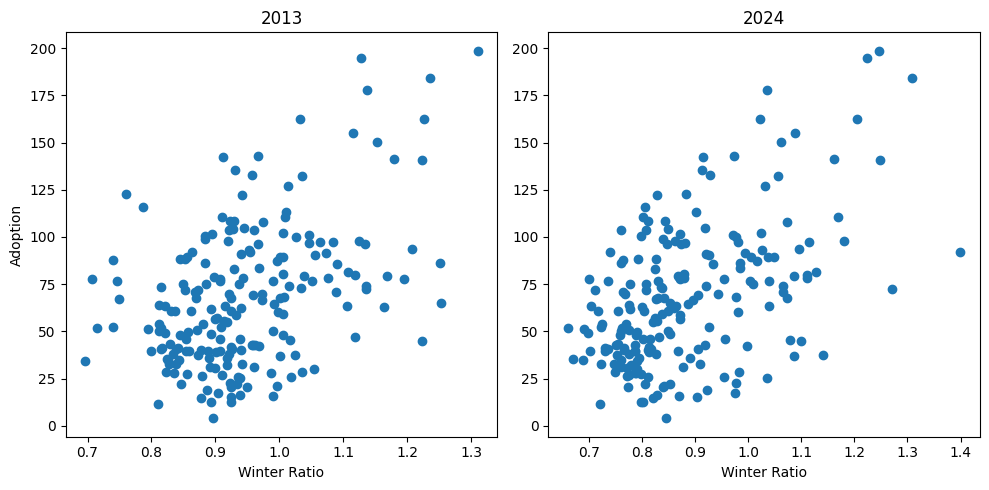

In [16]:
plt.figure(figsize=(10,5))

# 2013
plt.subplot(1,2,1)
plt.scatter(
    df_2013_clean["Winter_Summer_Ratio"],
    df_2013_clean["installs_per_1000"]
)
plt.title("2013")
plt.xlabel("Winter Ratio")
plt.ylabel("Adoption")

# 2024
plt.subplot(1,2,2)
plt.scatter(
    df_2024_clean["winter_summer_ratio"],
    df_2024_clean["installs_per_1000"]
)
plt.title("2024")
plt.xlabel("Winter Ratio")

plt.tight_layout()
plt.show()

In [17]:
df_merge = pd.merge(
    df_2024_clean,
    df_2013_clean,
    on="municipality",
    suffixes=("_2024", "_2013")
)

print(df_merge.shape)
df_merge.head()

(246, 26)


,municipality,winter_mwh,summer_mwh,winter_summer_ratio,hp_accounts_2024,hp_locations,households_2024,electric_fuel_2024,gas_fuel_2024,delivered_fuels_2024,...,Highest_Winter_Month,Summer_Avg_MWh,Highest_Winter_Month_Ratio,hp_accounts_2013,households_2013,electric_fuel_2013,gas_fuel_2013,delivered_fuels_2013,installs_per_1000_2013,is_tourist_2013
0,abington,12448.0,15969.0,0.779510,209.0,202.0,6438.0,1053.0,2774.0,2570.0,...,8434.0,8331.333333,1.012323,209.0,6438.0,1053.0,2774.0,2570.0,32.463498,False
1,acton,19043.0,20368.0,0.934947,780.0,765.0,9085.0,1483.0,4787.0,2815.0,...,19662.0,14844.000000,1.324576,780.0,9085.0,1483.0,4787.0,2815.0,85.855806,False
2,acushnet,7597.0,9960.0,0.762751,213.0,208.0,4103.0,148.0,1758.0,2066.0,...,3966.0,4425.333333,0.896204,213.0,4103.0,148.0,1758.0,2066.0,51.913234,False
3,adams,5899.0,6183.0,0.954068,105.0,100.0,4081.0,333.0,2156.0,1547.0,...,8306.0,7884.000000,1.053526,105.0,4081.0,333.0,2156.0,1547.0,25.728988,False
4,agawam,22022.0,27900.0,0.789319,332.0,329.0,11792.0,2154.0,6512.0,3023.0,...,22348.0,24498.333330,0.912225,332.0,11792.0,2154.0,6512.0,3023.0,28.154681,False


In [18]:
df_2024_clean = df_2024_clean.rename(columns={
    "winter_summer_ratio": "winter_ratio_2024"
})

df_2013_clean = df_2013_clean.rename(columns={
    "Winter_Summer_Ratio": "winter_ratio_2013"
})

In [19]:
df_merge = pd.merge(
    df_2024_clean,
    df_2013_clean,
    on="municipality"
)

In [20]:
df_merge["winter_ratio_change"] = (
    df_merge["winter_ratio_2024"] -
    df_merge["winter_ratio_2013"]
)

In [21]:
df_merge = df_merge.rename(columns={
    "installs_per_1000_x": "installs_per_1000_2024",
    "installs_per_1000_y": "installs_per_1000_2013"
})

In [22]:
# Rename before merge
df_2024_clean = df_2024_clean.rename(columns={
    "winter_summer_ratio": "winter_ratio_2024"
})

df_2013_clean = df_2013_clean.rename(columns={
    "Winter_Summer_Ratio": "winter_ratio_2013"
})

# Merge
df_merge = pd.merge(df_2024_clean, df_2013_clean, on="municipality")

# Fix install column names
df_merge = df_merge.rename(columns={
    "installs_per_1000_x": "installs_per_1000_2024",
    "installs_per_1000_y": "installs_per_1000_2013"
})

# Create change variable
df_merge["winter_ratio_change"] = (
    df_merge["winter_ratio_2024"] -
    df_merge["winter_ratio_2013"]
)

In [23]:
df_merge[["winter_ratio_change", "installs_per_1000_2024"]].corr()

,winter_ratio_change,installs_per_1000_2024
winter_ratio_change,1.000000,0.217155
installs_per_1000_2024,0.217155,1.000000


In [24]:
print(df_merge.columns)

Index(['municipality', 'winter_mwh', 'summer_mwh', 'winter_ratio_2024',
       'hp_accounts_x', 'hp_locations', 'households_x', 'electric_fuel_x',
       'gas_fuel_x', 'delivered_fuels_x', 'installs_per_1000_2024',
       'is_tourist_x', 'Annual_MWh', 'Winter_MWh', 'Summer_MWh',
       'winter_ratio_2013', 'Highest_Winter_Month', 'Summer_Avg_MWh',
       'Highest_Winter_Month_Ratio', 'hp_accounts_y', 'households_y',
       'electric_fuel_y', 'gas_fuel_y', 'delivered_fuels_y',
       'installs_per_1000_2013', 'is_tourist_y', 'winter_ratio_change'],
      dtype='object')


In [25]:
df_merge = df_merge.rename(columns={
    "electric_fuel_x": "electric_fuel_2024",
    "gas_fuel_x": "gas_fuel_2024",
    "delivered_fuels_x": "delivered_fuels_2024",
    "electric_fuel_y": "electric_fuel_2013",
    "gas_fuel_y": "gas_fuel_2013",
    "delivered_fuels_y": "delivered_fuels_2013",
    "households_x": "households_2024",
    "households_y": "households_2013",
    "hp_accounts_x": "hp_accounts_2024",
    "hp_accounts_y": "hp_accounts_2013",
    "is_tourist_x": "is_tourist_2024",
    "is_tourist_y": "is_tourist_2013"
})

In [26]:
df_merge["delivered_change"] = (
    df_merge["delivered_fuels_2024"] - df_merge["delivered_fuels_2013"]
)

df_merge["gas_change"] = (
    df_merge["gas_fuel_2024"] - df_merge["gas_fuel_2013"]
)

df_merge["electric_change"] = (
    df_merge["electric_fuel_2024"] - df_merge["electric_fuel_2013"]
)

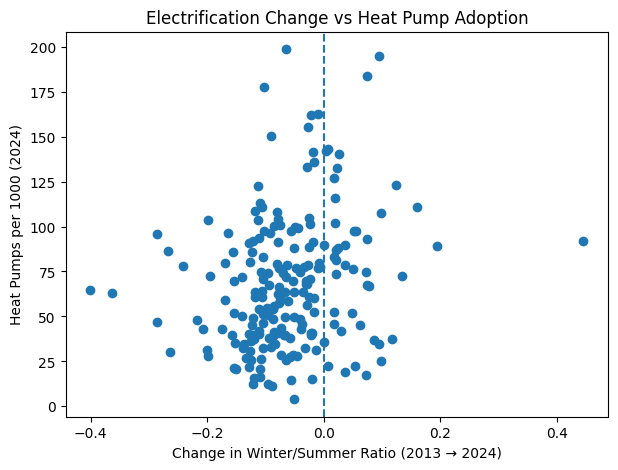

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))
plt.scatter(df_merge["winter_ratio_change"], df_merge["installs_per_1000_2024"])
plt.xlabel("Change in Winter/Summer Ratio (2013 → 2024)")
plt.ylabel("Heat Pumps per 1000 (2024)")
plt.title("Electrification Change vs Heat Pump Adoption")
plt.axvline(0, linestyle="--")
plt.show()

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------
# 1. Rename merged columns clearly
# ----------------------------
df_merge = df_merge.rename(columns={
    "electric_fuel_x": "electric_fuel_2024",
    "gas_fuel_x": "gas_fuel_2024",
    "delivered_fuels_x": "delivered_fuels_2024",
    "electric_fuel_y": "electric_fuel_2013",
    "gas_fuel_y": "gas_fuel_2013",
    "delivered_fuels_y": "delivered_fuels_2013",
    "households_x": "households_2024",
    "households_y": "households_2013",
    "hp_accounts_x": "hp_accounts_2024",
    "hp_accounts_y": "hp_accounts_2013",
    "is_tourist_x": "is_tourist_2024",
    "is_tourist_y": "is_tourist_2013"
})

# ----------------------------
# 2. Create change variables
# ----------------------------
df_merge["delivered_households_change"] = (
    df_merge["delivered_fuels_2024"] - df_merge["delivered_fuels_2013"]
)

df_merge["gas_households_change"] = (
    df_merge["gas_fuel_2024"] - df_merge["gas_fuel_2013"]
)

df_merge["electric_households_change"] = (
    df_merge["electric_fuel_2024"] - df_merge["electric_fuel_2013"]
)

# optional: check a few rows
df_merge[[
    "municipality",
    "delivered_fuels_2013", "delivered_fuels_2024", "delivered_households_change",
    "gas_fuel_2013", "gas_fuel_2024", "gas_households_change",
    "electric_fuel_2013", "electric_fuel_2024", "electric_households_change"
]].head()

,municipality,delivered_fuels_2013,delivered_fuels_2024,delivered_households_change,gas_fuel_2013,gas_fuel_2024,gas_households_change,electric_fuel_2013,electric_fuel_2024,electric_households_change
0,abington,2570.0,2570.0,0.0,2774.0,2774.0,0.0,1053.0,1053.0,0.0
1,acton,2815.0,2815.0,0.0,4787.0,4787.0,0.0,1483.0,1483.0,0.0
2,acushnet,2066.0,2066.0,0.0,1758.0,1758.0,0.0,148.0,148.0,0.0
3,adams,1547.0,1547.0,0.0,2156.0,2156.0,0.0,333.0,333.0,0.0
4,agawam,3023.0,3023.0,0.0,6512.0,6512.0,0.0,2154.0,2154.0,0.0


In [29]:
print(df_merge.columns)

Index(['municipality', 'winter_mwh', 'summer_mwh', 'winter_ratio_2024',
       'hp_accounts_2024', 'hp_locations', 'households_2024',
       'electric_fuel_2024', 'gas_fuel_2024', 'delivered_fuels_2024',
       'installs_per_1000_2024', 'is_tourist_2024', 'Annual_MWh', 'Winter_MWh',
       'Summer_MWh', 'winter_ratio_2013', 'Highest_Winter_Month',
       'Summer_Avg_MWh', 'Highest_Winter_Month_Ratio', 'hp_accounts_2013',
       'households_2013', 'electric_fuel_2013', 'gas_fuel_2013',
       'delivered_fuels_2013', 'installs_per_1000_2013', 'is_tourist_2013',
       'winter_ratio_change', 'delivered_change', 'gas_change',
       'electric_change', 'delivered_households_change',
       'gas_households_change', 'electric_households_change'],
      dtype='object')


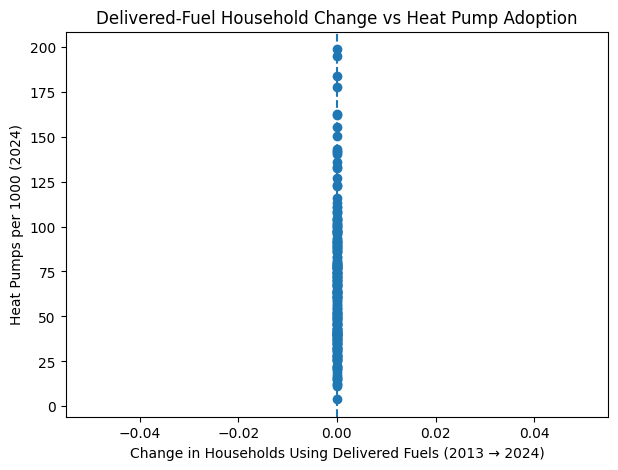

In [30]:
plt.figure(figsize=(7,5))
plt.scatter(df_merge["delivered_households_change"], df_merge["installs_per_1000_2024"])
plt.xlabel("Change in Households Using Delivered Fuels (2013 → 2024)")
plt.ylabel("Heat Pumps per 1000 (2024)")
plt.title("Delivered-Fuel Household Change vs Heat Pump Adoption")
plt.axvline(0, linestyle="--")
plt.show()

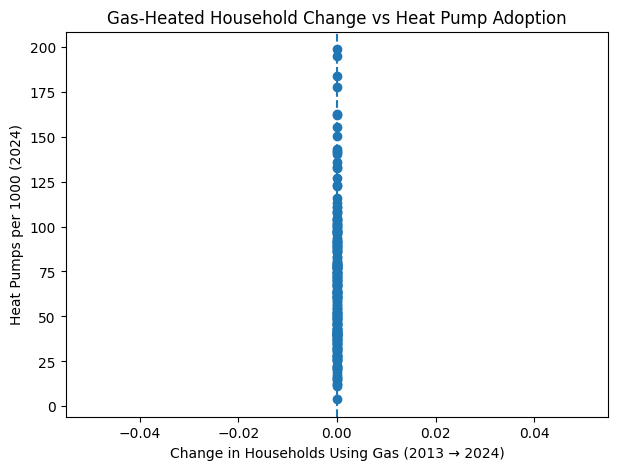

In [31]:
plt.figure(figsize=(7,5))
plt.scatter(df_merge["gas_households_change"], df_merge["installs_per_1000_2024"])
plt.xlabel("Change in Households Using Gas (2013 → 2024)")
plt.ylabel("Heat Pumps per 1000 (2024)")
plt.title("Gas-Heated Household Change vs Heat Pump Adoption")
plt.axvline(0, linestyle="--")
plt.show()

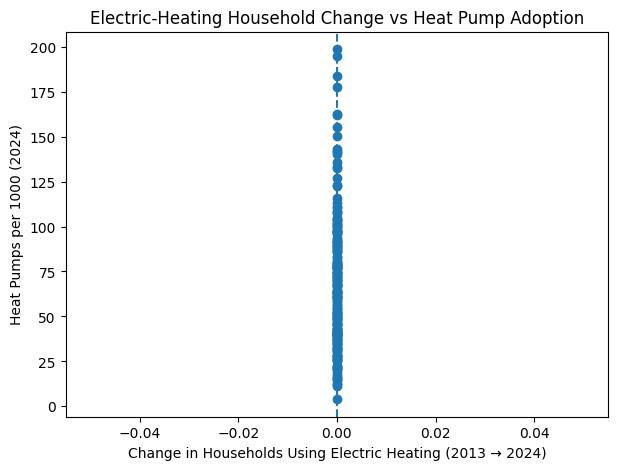

In [32]:
plt.figure(figsize=(7,5))
plt.scatter(df_merge["electric_households_change"], df_merge["installs_per_1000_2024"])
plt.xlabel("Change in Households Using Electric Heating (2013 → 2024)")
plt.ylabel("Heat Pumps per 1000 (2024)")
plt.title("Electric-Heating Household Change vs Heat Pump Adoption")
plt.axvline(0, linestyle="--")
plt.show()

In [33]:
df_merge["delivered_share_2024"] = (
    df_merge["delivered_fuels_2024"] / df_merge["households_2024"]
)

df_merge["gas_share_2024"] = (
    df_merge["gas_fuel_2024"] / df_merge["households_2024"]
)

In [34]:
df_final = df_merge[[
    "municipality",

    # 2013
    "winter_ratio_2013",
    "electric_fuel_2013",
    "gas_fuel_2013",
    "delivered_fuels_2013",

    # 2024
    "winter_ratio_2024",
    "electric_fuel_2024",
    "gas_fuel_2024",
    "delivered_fuels_2024",
    "installs_per_1000_2024",

    # change
    "winter_ratio_change",
    "delivered_households_change",
    "gas_households_change",
    "electric_households_change"
]]

df_final.to_csv("ma_heatpump_master_dataset.csv", index=False)

In [35]:
df_merge["delivered_share"] = df_merge["delivered_fuels_2024"] / df_merge["households_2024"]
df_merge["gas_share"] = df_merge["gas_fuel_2024"] / df_merge["households_2024"]

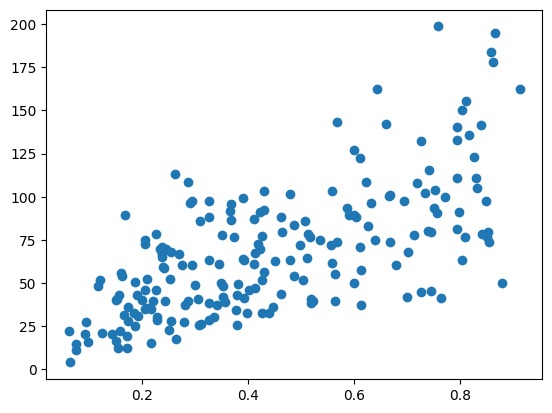

In [36]:
plt.scatter(df_merge["delivered_share"], df_merge["installs_per_1000_2024"])

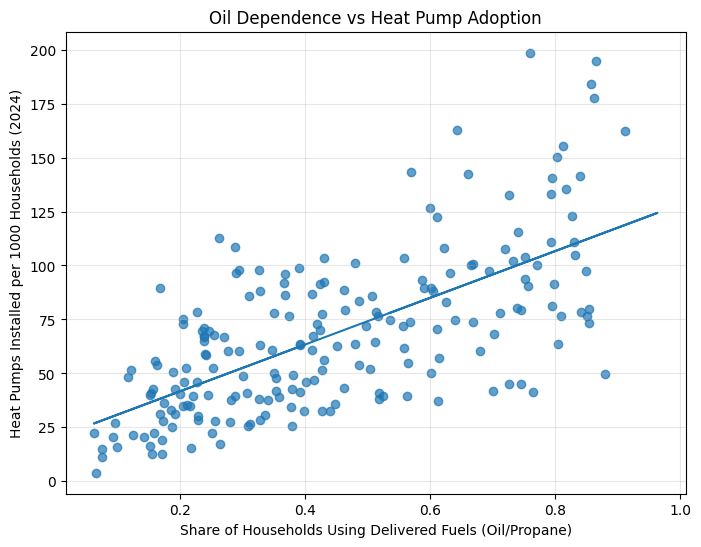

In [37]:
import numpy as np

plt.figure(figsize=(8,6))

x = df_merge["delivered_share"]
y = df_merge["installs_per_1000_2024"]

plt.scatter(x, y, alpha=0.7)

# trend line (safe version)
mask = ~np.isnan(x) & ~np.isnan(y)
m, b = np.polyfit(x[mask], y[mask], 1)
plt.plot(x, m*x + b)

plt.xlabel("Share of Households Using Delivered Fuels (Oil/Propane)")
plt.ylabel("Heat Pumps Installed per 1000 Households (2024)")
plt.title("Oil Dependence vs Heat Pump Adoption")

plt.grid(alpha=0.3)

plt.show()

In [38]:
df_merge[
    df_merge["delivered_fuels_2024"] > 20000
][["municipality", "delivered_fuels_2024", "installs_per_1000_2024"]]

,municipality,delivered_fuels_2024,installs_per_1000_2024
29,boston,27690.0,16.012693


In [39]:
df_merge.sort_values("winter_ratio_change", ascending=False)[
    ["municipality", "winter_ratio_change", "installs_per_1000_2024"]
].head(5)

,municipality,winter_ratio_change,installs_per_1000_2024
6,amherst,0.445998,91.824317
150,northampton,0.194130,89.348451
165,plainfield,0.190757,NaN
239,williamsburg,0.160527,110.815603
199,sunderland,0.134371,72.706935


Text(0.44599845399750937, 91.82431685, 'amherst')

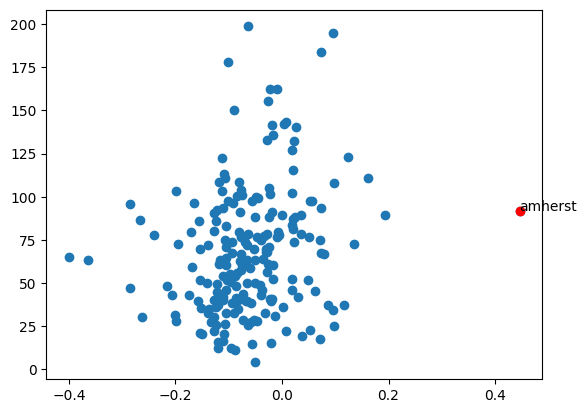

In [40]:
outlier = df_merge.loc[df_merge["winter_ratio_change"].idxmax()]

plt.scatter(df_merge["winter_ratio_change"], df_merge["installs_per_1000_2024"])
plt.scatter(outlier["winter_ratio_change"], outlier["installs_per_1000_2024"], color="red")

plt.annotate(outlier["municipality"],
             (outlier["winter_ratio_change"], outlier["installs_per_1000_2024"]))

---
## Original analysis section: `partial_analysis(1).ipynb`

**What this section contains:** Exploration of full-displacement, partial-displacement, and overall adoption measures, including high-adoption towns and coastal/inland comparisons.

> The code and outputs below are preserved from the original notebook/work file. They have not been rewritten or re-derived for this polished repository version.


In [1]:
from google.colab import files
uploaded = files.upload()

Saving final_dataset_clean.csv to final_dataset_clean.csv


In [3]:
import pandas as pd

df = pd.read_csv("final_dataset_clean.csv")
df.head()

,municipality,total_households_2023,electric_fuel_2023,gas_fuel_2023,delivered_fuels_2023,electric_share_2023,gas_share_2023,delivered_share_2023,installs_per_1000_2023,total_households_2024,...,winter_hdd_2023,winter_hdd_2024,electricity_per_HDD_2013,electricity_per_HDD_2023,electricity_per_HDD_2024,electricity_per_HDD_change_13_23,electricity_per_HDD_change_13_24,elec_per_hh_per_hdd_2023,installs_per_1000_full_disp_2024,hp_accounts_full_disp_2024
0,wellfleet,1924,236,72,1400,0.122661,0.037422,0.727651,295.738046,2069,...,2587.4028,2732.6106,1.833891,1.971089,2.136419,0.137198,0.302528,0.001024,66.698888,138.0
1,oak bluffs,2064,259,167,1424,0.125484,0.080911,0.689922,156.492248,1944,...,2587.4028,2732.6106,3.807210,3.348532,3.594731,-0.458679,-0.212479,0.001622,56.069959,109.0
2,tisbury,1886,293,0,1437,0.155355,0.000000,0.761930,165.959703,1912,...,2587.4028,2732.6106,3.017226,2.727059,3.034827,-0.290167,0.017601,0.001446,53.870293,103.0
3,eastham,2860,463,1170,1214,0.161888,0.409091,0.424476,219.930070,3041,...,2587.4028,2732.6106,2.986716,2.744837,2.956513,-0.241879,-0.030203,0.000960,49.325880,150.0
4,dennis,7116,1181,4878,1016,0.165964,0.685497,0.142777,147.414278,7302,...,2587.4028,2732.6106,8.066168,6.397535,6.726169,-1.668633,-1.339999,0.000899,34.237195,250.0


In [4]:
print(df.shape)
print(df.columns)
df.isna().sum()

(351, 52)
Index(['municipality', 'total_households_2023', 'electric_fuel_2023',
       'gas_fuel_2023', 'delivered_fuels_2023', 'electric_share_2023',
       'gas_share_2023', 'delivered_share_2023', 'installs_per_1000_2023',
       'total_households_2024', 'electric_fuel_2024', 'gas_fuel_2024',
       'delivered_fuels_2024', 'electric_share_2024', 'gas_share_2024',
       'delivered_share_2024', 'installs_per_1000_2024',
       'electric_share_change_23_24', 'gas_share_change_23_24',
       'delivered_share_change_23_24', 'adoption_change_23_24',
       'total_households_2013', 'electric_fuel_2013', 'gas_fuel_2013',
       'delivered_fuels_2013', 'electric_share_2013', 'gas_share_2013',
       'delivered_share_2013', 'delivered_share_change_13_23',
       'gas_share_change_13_23', 'electric_share_change_13_23',
       'delivered_share_change_13_24', 'gas_share_change_13_24',
       'electric_share_change_13_24', 'wsr_2013', 'wsr_2023', 'wsr_2024',
       'winter_mwh_2013', 'winter_mwh

,0
municipality,0
total_households_2023,0
electric_fuel_2023,0
gas_fuel_2023,0
delivered_fuels_2023,0
electric_share_2023,0
gas_share_2023,0
delivered_share_2023,0
installs_per_1000_2023,103
total_households_2024,0


In [6]:
required_cols = [
    "municipality",
    "total_households_2024",
    "installs_per_1000_2024",
    "elec_per_hh_per_hdd_2023",   # <- updated
    "delivered_share_2013",
    "gas_share_2013"
]

for col in required_cols:
    print(col, "✅" if col in df.columns else "❌")

municipality ✅
total_households_2024 ✅
installs_per_1000_2024 ✅
elec_per_hh_per_hdd_2023 ✅
delivered_share_2013 ✅
gas_share_2013 ✅


In [7]:
extra_cols = [
    "installs_per_1000_full_disp_2024",
    "hp_accounts_full_disp_2024"
]

for col in extra_cols:
    print(col, "✅" if col in df.columns else "❌")

installs_per_1000_full_disp_2024 ✅
hp_accounts_full_disp_2024 ✅


In [9]:
df = df.rename(columns={
    "elec_per_hh_per_hdd_2023": "electricity_per_hh_per_hdd_2023"
})

In [10]:
top5_full_disp = (
    df.dropna(subset=["installs_per_1000_full_disp_2024"])
    .sort_values("installs_per_1000_full_disp_2024", ascending=False)
    [[
        "municipality",
        "installs_per_1000_full_disp_2024",
        "hp_accounts_full_disp_2024",
        "total_households_2024",
        "electricity_per_hh_per_hdd_2023",
        "delivered_share_2013",
        "gas_share_2013"
    ]]
    .head(5)
)

top5_full_disp

,municipality,installs_per_1000_full_disp_2024,hp_accounts_full_disp_2024,total_households_2024,electricity_per_hh_per_hdd_2023,delivered_share_2013,gas_share_2013
0,wellfleet,66.698888,138.0,2069,0.001024,0.805210,0.046181
1,oak bluffs,56.069959,109.0,1944,0.001622,0.656869,0.074985
2,tisbury,53.870293,103.0,1912,0.001446,0.777692,0.020914
3,eastham,49.325880,150.0,3041,0.000960,0.480728,0.398874
4,dennis,34.237195,250.0,7302,0.000899,0.195338,0.678647


In [11]:
top5_full_disp[[
    "municipality",
    "delivered_share_2013",
    "gas_share_2013",
    "electricity_per_hh_per_hdd_2023"
]]

,municipality,delivered_share_2013,gas_share_2013,electricity_per_hh_per_hdd_2023
0,wellfleet,0.805210,0.046181,0.001024
1,oak bluffs,0.656869,0.074985,0.001622
2,tisbury,0.777692,0.020914,0.001446
3,eastham,0.480728,0.398874,0.000960
4,dennis,0.195338,0.678647,0.000899


In [12]:
top15_full_disp = (
    df.dropna(subset=["installs_per_1000_full_disp_2024"])
    .sort_values("installs_per_1000_full_disp_2024", ascending=False)
    [[
        "municipality",
        "installs_per_1000_full_disp_2024",
        "electricity_per_hh_per_hdd_2023",
        "delivered_share_2013",
        "gas_share_2013"
    ]]
    .head(15)
)

top15_full_disp

,municipality,installs_per_1000_full_disp_2024,electricity_per_hh_per_hdd_2023,delivered_share_2013,gas_share_2013
0,wellfleet,66.698888,0.001024,0.805210,0.046181
1,oak bluffs,56.069959,0.001622,0.656869,0.074985
2,tisbury,53.870293,0.001446,0.777692,0.020914
3,eastham,49.325880,0.000960,0.480728,0.398874
4,dennis,34.237195,0.000899,0.195338,0.678647
5,rutland,33.281005,0.000820,0.703704,0.019435
6,brewster,31.363345,0.001014,0.515832,0.339792
7,sandwich,30.812989,0.000823,0.453986,0.457464
8,falmouth,30.288784,0.000847,0.415759,0.495473
9,southborough,29.917924,0.000943,0.606246,0.333435


In [13]:
# Cluster 1: Coastal / tourist towns
coastal_towns = [
    "wellfleet", "provincetown", "truro", "eastham", "chatham",
    "dennis", "yarmouth", "barnstable", "falmouth",
    "oak bluffs", "tisbury", "edgartown", "west tisbury", "chilmark", "aquinnah", "gosnold",
    "brewster", "sandwich", "bourne", "harwich"
]

# Cluster 2: Inland high-adoption towns (from your result)
inland_high_adoption = [
    "rutland", "southborough", "montague", "wayland", "holliston"
]

In [14]:
df["cluster"] = "Other"

df.loc[df["municipality"].isin(coastal_towns), "cluster"] = "Coastal (Tourist, Oil-dependent)"

df.loc[df["municipality"].isin(inland_high_adoption), "cluster"] = "Inland (High adoption, Non-tourist)"

In [15]:
cluster_df = df[
    df["municipality"].isin(coastal_towns + inland_high_adoption)
].copy()

In [16]:
cluster_df = cluster_df.sort_values(
    "installs_per_1000_full_disp_2024",
    ascending=False
)

In [17]:
cluster_df.to_csv("cluster_analysis_full_dataset.csv", index=False)

In [18]:
from google.colab import files
files.download("cluster_analysis_full_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
cluster_summary = cluster_df.groupby("cluster")[[
    "installs_per_1000_full_disp_2024",
    "electricity_per_hh_per_hdd_2023",
    "delivered_share_2013",
    "gas_share_2013"
]].mean()

cluster_summary

,installs_per_1000_full_disp_2024,electricity_per_hh_per_hdd_2023,delivered_share_2013,gas_share_2013
cluster,,,,
"Coastal (Tourist, Oil-dependent)",37.681494,0.001299,0.555083,0.300360
"Inland (High adoption, Non-tourist)",28.968040,0.000856,0.513716,0.341127


In [20]:
top5_overall = (
    df.dropna(subset=["installs_per_1000_2024"])
    .sort_values("installs_per_1000_2024", ascending=False)
    [[
        "municipality",
        "installs_per_1000_2024",
        "total_households_2024",
        "electricity_per_hh_per_hdd_2023",
        "delivered_share_2013",
        "gas_share_2013"
    ]]
    .head(5)
)

top5_overall

,municipality,installs_per_1000_2024,total_households_2024,electricity_per_hh_per_hdd_2023,delivered_share_2013,gas_share_2013
103,truro,404.360753,1009,0.001644,0.838359,0.033776
104,provincetown,276.245767,2067,0.001122,0.687027,0.169866
0,wellfleet,275.012083,2069,0.001024,0.805210,0.046181
108,pelham,212.686567,536,0.001000,0.706087,0.024348
106,edgartown,209.406495,1786,0.002892,0.788326,0.054852


In [21]:
top15_overall = (
    df.dropna(subset=["installs_per_1000_2024"])
    .sort_values("installs_per_1000_2024", ascending=False)
    [[
        "municipality",
        "installs_per_1000_2024",
        "electricity_per_hh_per_hdd_2023",
        "delivered_share_2013",
        "gas_share_2013"
    ]]
    .head(15)
)

top15_overall

,municipality,installs_per_1000_2024,electricity_per_hh_per_hdd_2023,delivered_share_2013,gas_share_2013
103,truro,404.360753,0.001644,0.838359,0.033776
104,provincetown,276.245767,0.001122,0.687027,0.169866
0,wellfleet,275.012083,0.001024,0.805210,0.046181
108,pelham,212.686567,0.001000,0.706087,0.024348
106,edgartown,209.406495,0.002892,0.788326,0.054852
3,eastham,206.839855,0.000960,0.480728,0.398874
107,chilmark,198.952880,0.002420,0.782209,0.021472
109,leverett,195.224719,0.001032,0.664894,0.011968
105,west tisbury,192.585895,0.002263,0.717151,0.005015
110,shutesbury,185.676393,0.000852,0.581769,0.008043


In [22]:
tourist_towns = [
    "wellfleet", "provincetown", "truro", "eastham", "chatham",
    "dennis", "yarmouth", "barnstable", "falmouth",
    "oak bluffs", "tisbury", "edgartown", "west tisbury", "chilmark", "aquinnah", "gosnold",
    "brewster", "sandwich", "bourne", "harwich"
]

In [23]:
non_tourist_overall = top15_overall[
    ~top15_overall["municipality"].isin(tourist_towns)
]

top5_non_tourist_overall = non_tourist_overall.head(5)

top5_non_tourist_overall

,municipality,installs_per_1000_2024,electricity_per_hh_per_hdd_2023,delivered_share_2013,gas_share_2013
108,pelham,212.686567,0.001000,0.706087,0.024348
109,leverett,195.224719,0.001032,0.664894,0.011968
110,shutesbury,185.676393,0.000852,0.581769,0.008043
111,gill,180.277350,0.000638,0.663701,0.016014
116,otis,163.323782,0.001358,0.618574,0.034826


In [27]:
# Top 15 from full displacement
top15_full_disp = (
    df.dropna(subset=["installs_per_1000_full_disp_2024"])
    .sort_values("installs_per_1000_full_disp_2024", ascending=False)
    [["municipality", "installs_per_1000_full_disp_2024"]]
    .head(15)
)

# tourist towns (same list as before)
tourist_towns = [
    "wellfleet", "provincetown", "truro", "eastham", "chatham",
    "dennis", "yarmouth", "barnstable", "falmouth",
    "oak bluffs", "tisbury", "edgartown", "west tisbury", "chilmark", "aquinnah", "gosnold",
    "brewster", "sandwich", "bourne", "harwich"
]

# filter inland
top5_non_tourist = (
    top15_full_disp[
        ~top15_full_disp["municipality"].isin(tourist_towns)
    ]
    .head(5)
)

top5_non_tourist

,municipality,installs_per_1000_full_disp_2024
5,rutland,33.281005
9,southborough,29.917924
11,montague,27.946217
12,wayland,27.657053
14,holliston,26.038001


In [28]:
top15_overall = (
    df.dropna(subset=["installs_per_1000_2024"])
    .sort_values("installs_per_1000_2024", ascending=False)
    [["municipality", "installs_per_1000_2024"]]
    .head(15)
)

top5_non_tourist_overall = (
    top15_overall[
        ~top15_overall["municipality"].isin(tourist_towns)
    ]
    .head(5)
)

top5_non_tourist_overall

,municipality,installs_per_1000_2024
108,pelham,212.686567
109,leverett,195.224719
110,shutesbury,185.676393
111,gill,180.277350
116,otis,163.323782


In [29]:
full_inland = set(top5_non_tourist["municipality"])
overall_inland = set(top5_non_tourist_overall["municipality"])

print("Common inland towns:", full_inland & overall_inland)
print("Only in full displacement:", full_inland - overall_inland)
print("Only in overall:", overall_inland - full_inland)

Common inland towns: set()
Only in full displacement: {'wayland', 'rutland', 'montague', 'holliston', 'southborough'}
Only in overall: {'pelham', 'otis', 'shutesbury', 'gill', 'leverett'}


In [30]:
# Coastal / tourist towns
tourist_towns = [
    "wellfleet", "provincetown", "truro", "eastham", "chatham",
    "dennis", "yarmouth", "barnstable", "falmouth",
    "oak bluffs", "tisbury", "edgartown", "west tisbury", "chilmark", "aquinnah", "gosnold",
    "brewster", "sandwich", "bourne", "harwich"
]

# Inland top towns from OVERALL adoption (your output)
inland_overall = ['pelham', 'otis', 'shutesbury', 'gill', 'leverett']

In [31]:
df["cluster_overall"] = "Other"

df.loc[df["municipality"].isin(tourist_towns),
       "cluster_overall"] = "Coastal (Tourist)"

df.loc[df["municipality"].isin(inland_overall),
       "cluster_overall"] = "Inland (High adoption - Overall)"

In [33]:
df.to_csv("final_dataset_with_overall_clusters.csv", index=False)

In [35]:
# 1. Tourist/coastal towns
tourist_towns = [
    "wellfleet", "provincetown", "truro", "eastham", "chatham",
    "dennis", "yarmouth", "barnstable", "falmouth",
    "oak bluffs", "tisbury", "edgartown", "west tisbury",
    "chilmark", "aquinnah", "gosnold",
    "brewster", "sandwich", "bourne", "harwich"
]

# 2. Top normal adoption towns
top_normal = (
    df.dropna(subset=["installs_per_1000_2024"])
      .sort_values("installs_per_1000_2024", ascending=False)
      .copy()
)

# 3. Take top 15 first, then identify inland top 5
top15_normal = top_normal.head(15)

top5_inland_normal = (
    top15_normal[~top15_normal["municipality"].isin(tourist_towns)]
    .head(5)
)

top5_coastal_normal = (
    top15_normal[top15_normal["municipality"].isin(tourist_towns)]
    .head(5)
)

print("Top 5 coastal normal adoption:")
display(top5_coastal_normal[["municipality", "installs_per_1000_2024"]])

print("Top 5 inland normal adoption:")
display(top5_inland_normal[["municipality", "installs_per_1000_2024"]])

Top 5 coastal normal adoption:


,municipality,installs_per_1000_2024
103,truro,404.360753
104,provincetown,276.245767
0,wellfleet,275.012083
106,edgartown,209.406495
3,eastham,206.839855


Top 5 inland normal adoption:


,municipality,installs_per_1000_2024
108,pelham,212.686567
109,leverett,195.224719
110,shutesbury,185.676393
111,gill,180.277350
116,otis,163.323782


In [36]:
# 4. Combine coastal + inland towns
normal_cluster_towns = pd.concat([
    top5_coastal_normal.assign(cluster="Coastal high adoption"),
    top5_inland_normal.assign(cluster="Inland high adoption")
])

# 5. Keep ALL columns from final dataset + cluster column
normal_cluster_csv = normal_cluster_towns.copy()

# 6. Sort by normal adoption metric
normal_cluster_csv = normal_cluster_csv.sort_values(
    "installs_per_1000_2024",
    ascending=False
)

# 7. Save
normal_cluster_csv.to_csv("normal_adoption_cluster_analysis.csv", index=False)

from google.colab import files
files.download("normal_adoption_cluster_analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:
from google.colab import files
files.upload()

Saving partial_disp_hvac.xlsx to partial_disp_hvac.xlsx


{'partial_disp_hvac.xlsx': b'PK\x03\x04\x14\x00\x00\x00\x08\x00\xc0b\x9d\\\x9b\xad\x13Z\xc7\x00\x00\x00\'\x01\x00\x00\x0f\x00\x1c\x00xl/workbook.xml \xa2\x18\x00(\xa0\x14\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x8d\x8fAN\xc30\x10E\xafb\xcd\x9e\xda\x85\x08J\x94\xa4\x9b\xb2\xe8\x96\x1b\x18{\xd2X\x8d=\xd6\x8c[r\xb7.8\x12W\xc0\x14D\xb7\xec\xfe\xff3\xfaz\xff\xf3\xf2\xd1m\x978\xab3\xb2\x04J=\xacW\x06\x14&G>\xa4C\x0f\xa72\xdem`;tK\xfbN||#:\xaa\xfa\x9f\xa4]z\x98J\xc9\xad\xd6\xe2&\x8cVV\x941\xd5\xdbH\x1cm\xa9\x96\x0fZ2\xa3\xf52!\x968\xeb{c\x1eu\xb4!\xc1w\xdf5\x95?\xa5\x92\x8d\xd8\xc3\xcb\x92\x89\x0b\xa8k\xb6\xf7\x15\x08\x14\xb7\xa1\x8aW\xf3\xb0y~j\xbc7\xce\xb8f\xdd8\xf8%\xe1\xff\x90\xd08\x06\x87;r\xa7\x88\xa9\xfc\xa00\xce\xb6\xd4\xd52\x85,\xa0\xf4\xd0\xe9\x1b\x96\xbe-\x1e\xbe\x00PK\x03\x04\n\x00\x00\x00\x00\x00\xc0b\x9d\\\x93\xa52+(\x01\x00\x00(\x01\x00\x00\x0b\x00\x1c\x00_rels/.rels \xa2\x18\x00(\xa0\x14\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x0

In [38]:
import pandas as pd

hp_partial = pd.read_excel("partial_disp_hvac.xlsx")
hp_partial.head()

/usr/local/lib/python3.12/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,Municipality,Installed heat pumps (accounts),Installed heat pumps (locations)
0,Abington,*,*
1,Acton,368,369
2,Acushnet,*,*
3,Adams,*,*
4,Agawam,*,*


In [39]:
hp_partial = hp_partial.rename(columns={
    "Municipality": "municipality",
    "Installed heat pumps (accounts)": "hp_accounts_partial_2024"
})

In [40]:
hp_partial = hp_partial[[
    "municipality",
    "hp_accounts_partial_2024"
]]

In [41]:
hp_partial["municipality"] = (
    hp_partial["municipality"]
    .str.lower()
    .str.strip()
)

In [42]:
import numpy as np

hp_partial["hp_accounts_partial_2024"] = (
    hp_partial["hp_accounts_partial_2024"]
    .replace("*", np.nan)
)

/tmp/ipykernel_23602/1121699192.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .replace("*", np.nan)


In [43]:
hp_partial["hp_accounts_partial_2024"] = pd.to_numeric(
    hp_partial["hp_accounts_partial_2024"],
    errors="coerce"
)

In [44]:
print(hp_partial.shape)
hp_partial.isna().sum()
hp_partial.head()

(343, 2)


,municipality,hp_accounts_partial_2024
0,abington,NaN
1,acton,368.0
2,acushnet,NaN
3,adams,NaN
4,agawam,NaN


In [45]:
df_partial = df.merge(
    hp_partial,
    on="municipality",
    how="left"
)

In [46]:
df_partial["installs_per_1000_partial_disp_2024"] = (
    df_partial["hp_accounts_partial_2024"] /
    df_partial["total_households_2024"] * 1000
)

In [47]:
# Full displacement
corr_full = df[[
    "electricity_per_hh_per_hdd_2023",
    "installs_per_1000_full_disp_2024"
]].corr().iloc[0,1]

# Partial displacement
corr_partial = df_partial[[
    "electricity_per_hh_per_hdd_2023",
    "installs_per_1000_partial_disp_2024"
]].corr().iloc[0,1]

# Overall
corr_overall = df[[
    "electricity_per_hh_per_hdd_2023",
    "installs_per_1000_2024"
]].corr().iloc[0,1]

print("Full displacement:", corr_full)
print("Partial displacement:", corr_partial)
print("Overall:", corr_overall)

Full displacement: 0.7333877857223056
Partial displacement: 0.7661811791094524
Overall: 0.6116557177525805
